In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Student Performance Prediction Project")
print("Libraries imported successfully!")

In [2]:
import pandas as pd

file_path = "Student_Performance_Predictive_Modeling.xlsx"

df = pd.read_excel(file_path, sheet_name="Student_Data")

df.head()

ImportError: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.

In [3]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd

file_path = "Student_Performance_Predictive_Modeling.xlsx"

df = pd.read_excel(file_path, sheet_name="Student_Data")

df.head()

,Student_ID,Age,Study_Hours_Per_Week,Attendance_Percent,Previous_Failures,Absences,Previous_Test_Score,Final_Result
0,1,17,8,92,2,0,88,Pass
1,2,18,3,65,1,1,58,Fail
2,3,16,10,96,0,0,94,Pass
3,4,19,2,55,3,2,49,Fail
4,5,17,6,85,1,0,79,Pass


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFinal Result Distribution:")
print(df["Final_Result"].value_counts())

Dataset Shape: (50, 8)

Column Names:
['Student_ID', 'Age', 'Study_Hours_Per_Week', 'Attendance_Percent', 'Previous_Failures', 'Absences', 'Previous_Test_Score', 'Final_Result']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Student_ID            50 non-null     int64
 1   Age                   50 non-null     int64
 2   Study_Hours_Per_Week  50 non-null     int64
 3   Attendance_Percent    50 non-null     int64
 4   Previous_Failures     50 non-null     int64
 5   Absences              50 non-null     int64
 6   Previous_Test_Score   50 non-null     int64
 7   Final_Result          50 non-null     str  
dtypes: int64(7), str(1)
memory usage: 3.3 KB

Missing Values:
Student_ID              0
Age                     0
Study_Hours_Per_Week    0
Attendance_Percent      0
Previous_Failures       0
Absences                0


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Final_Result")

plt.title("Student Pass and Fail Distribution")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")

plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [7]:
%pip install seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


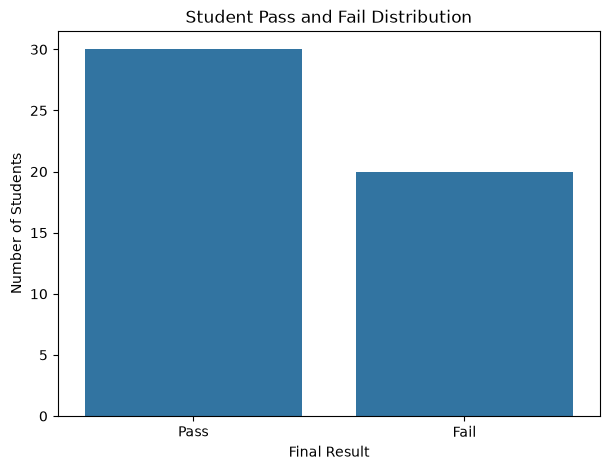

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(
    "Student_Performance_Predictive_Modeling.xlsx",
    sheet_name="Student_Data"
)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Final_Result")

plt.title("Student Pass and Fail Distribution")
plt.xlabel("Final Result")
plt.ylabel("Number of Students")
plt.show()

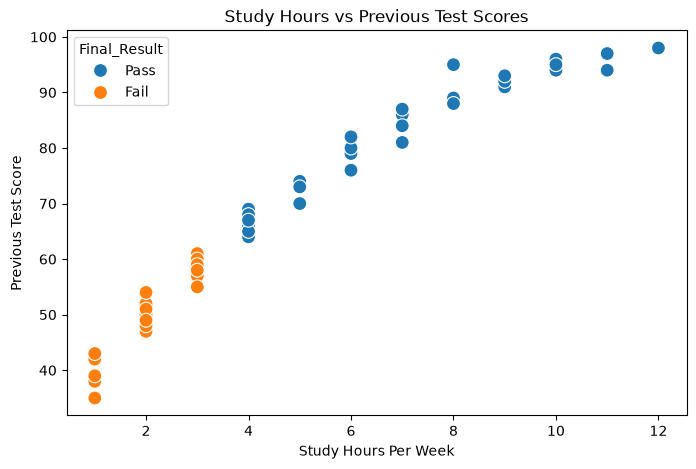

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Study_Hours_Per_Week",
    y="Previous_Test_Score",
    hue="Final_Result",
    s=100
)

plt.title("Study Hours vs Previous Test Scores")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Previous Test Score")
plt.show()

In [10]:
X = df[
    [
        "Age",
        "Study_Hours_Per_Week",
        "Attendance_Percent",
        "Previous_Failures",
        "Absences",
        "Previous_Test_Score"
    ]
]

y = df["Final_Result"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget values:")
display(y.head())

Input features shape: (50, 6)
Target shape: (50,)

Input features:


,Age,Study_Hours_Per_Week,Attendance_Percent,Previous_Failures,Absences,Previous_Test_Score
0,17,8,92,2,0,88
1,18,3,65,1,1,58
2,16,10,96,0,0,94
3,19,2,55,3,2,49
4,17,6,85,1,0,79



Target values:


0    Pass
1    Fail
2    Pass
3    Fail
4    Pass
Name: Final_Result, dtype: str

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 40
Testing records: 10


In [12]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [13]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_dt = dt_model.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(accuracy_dt * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

Decision Tree Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         4
        Pass       1.00      1.00      1.00         6

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [15]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(accuracy_rf * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         4
        Pass       1.00      1.00      1.00         6

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



,Model,Accuracy (%)
0,Decision Tree,100.0
1,Random Forest,100.0


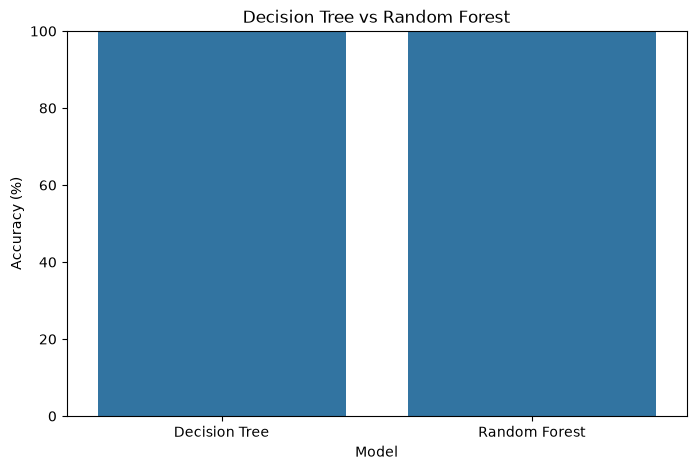

In [16]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy (%)": [
        accuracy_dt * 100,
        accuracy_rf * 100
    ]
})

display(results)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

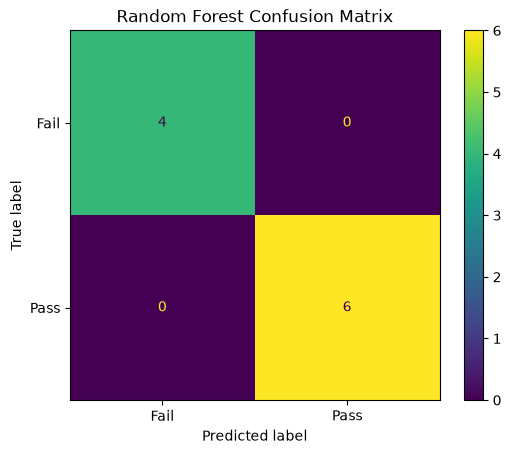

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=["Fail", "Pass"]
)

display_labels = ["Fail", "Pass"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

In [18]:

new_student = pd.DataFrame([{
    "Age": 18,
    "Study_Hours_Per_Week": 7,
    "Attendance_Percent": 90,
    "Previous_Failures": 0,
    "Absences": 2,
    "Previous_Test_Score": 80
}])

print("New Student Details:")
display(new_student)

New Student Details:


,Age,Study_Hours_Per_Week,Attendance_Percent,Previous_Failures,Absences,Previous_Test_Score
0,18,7,90,0,2,80


In [19]:
prediction = rf_model.predict(new_student)

print("Predicted Student Result:", prediction[0])

Predicted Student Result: Pass


In [20]:
probabilities = rf_model.predict_proba(new_student)[0]

for class_name, probability in zip(rf_model.classes_, probabilities):
    print(f"{class_name}: {probability * 100:.2f}%")

Fail: 9.00%
Pass: 91.00%


,Feature,Importance
1,Study_Hours_Per_Week,0.303877
5,Previous_Test_Score,0.297046
2,Attendance_Percent,0.207194
4,Absences,0.130653
3,Previous_Failures,0.061159
0,Age,0.000071


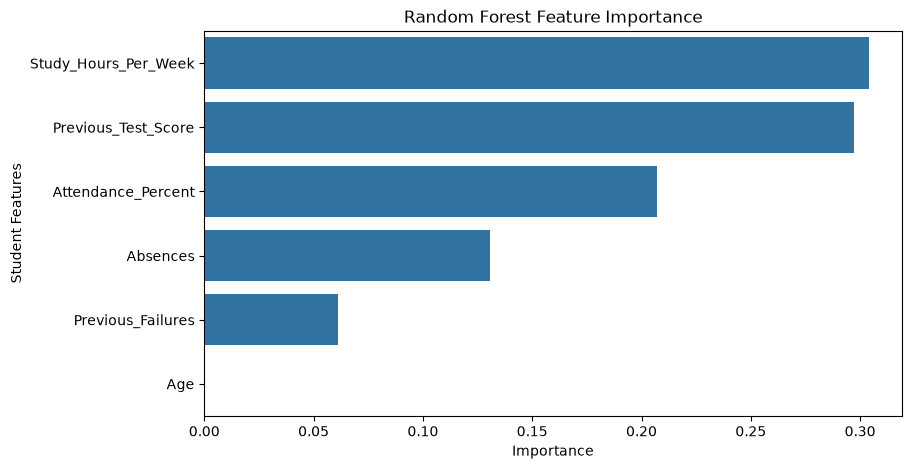

In [21]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="Importance", y="Feature")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Student Features")
plt.show()

In [22]:
import joblib

joblib.dump(rf_model, "student_performance_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [23]:
%pip install ipywidgets


   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   -------------------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [25]:
import ipywidgets as widgets
from IPython.display import display, clear_output

age_input = widgets.IntSlider(
    value=18, min=15, max=25, description="Age:"
)

study_input = widgets.IntSlider(
    value=7, min=0, max=40, description="Study Hours:"
)

attendance_input = widgets.IntSlider(
    value=90, min=0, max=100, description="Attendance:"
)

failures_input = widgets.IntSlider(
    value=0, min=0, max=5, description="Previous Failures:"
)

absences_input = widgets.IntSlider(
    value=2, min=0, max=30, description="Absences:"
)

score_input = widgets.IntSlider(
    value=80, min=0, max=100, description="Previous Score:"
)

predict_button = widgets.Button(
    description="Predict Result",
    button_style="success"
)

output = widgets.Output()

def predict_student_result(button):
    with output:
        clear_output(wait=True)

        student = pd.DataFrame([{
            "Age": age_input.value,
            "Study_Hours_Per_Week": study_input.value,
            "Attendance_Percent": attendance_input.value,
            "Previous_Failures": failures_input.value,
            "Absences": absences_input.value,
            "Previous_Test_Score": score_input.value
        }])

        prediction = rf_model.predict(student)[0]
        probabilities = rf_model.predict_proba(student)[0]

        print("Predicted Result:", prediction)
        print("\nEstimated Model Probabilities:")

        for label, probability in zip(rf_model.classes_, probabilities):
            print(f"{label}: {probability * 100:.2f}%")

        print("\nNote: This is a demonstration using a small synthetic dataset.")

predict_button.on_click(predict_student_result)

display(
    age_input,
    study_input,
    attendance_input,
    failures_input,
    absences_input,
    score_input,
    predict_button,
    output
)

IntSlider(value=18, description='Age:', max=25, min=15)

IntSlider(value=7, description='Study Hours:', max=40)

IntSlider(value=90, description='Attendance:')

IntSlider(value=0, description='Previous Failures:', max=5)

IntSlider(value=2, description='Absences:', max=30)

IntSlider(value=80, description='Previous Score:')

Button(button_style='success', description='Predict Result', style=ButtonStyle())

Output()

In [26]:
Predicted Result: Pass

Estimated Model Probabilities:
Fail: XX.XX%
Pass: XX.XX%

SyntaxError: invalid syntax (1174545131.py, line 1)

In [27]:
prediction = rf_model.predict(new_student)

print("Predicted Result:", prediction[0])

Predicted Result: Pass


In [28]:
probabilities = rf_model.predict_proba(new_student)[0]

for label, probability in zip(rf_model.classes_, probabilities):
    print(f"{label}: {probability * 100:.2f}%")

Fail: 9.00%
Pass: 91.00%


In [29]:
import joblib

joblib.dump(rf_model, "student_performance_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [30]:
%pip install streamlit

  Using cached streamlit-1.66.1-py3-none-any.whl.metadata (10 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
Using cached streamlit-1.66.1-py3-none-any.whl (10.4 MB)
Using cached altair-6.3.0-py3-none-any.whl (797 kB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   -----------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [31]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [32]:
import streamlit as st
import pandas as pd
import joblib
import os

# -----------------------------
# PAGE CONFIGURATION
# -----------------------------
st.set_page_config(
    page_title="Student Performance Prediction",
    page_icon="🎓",
    layout="wide"
)

# -----------------------------
# LOAD TRAINED MODEL
# -----------------------------
MODEL_PATH = "student_performance_model.pkl"
DATA_PATH = "Student_Performance_Predictive_Modeling.xlsx"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

# -----------------------------
# HEADER
# -----------------------------
st.title("🎓 Student Performance Prediction System")

st.write(
    "Predict a student's academic result using a "
    "Random Forest machine learning model."
)

st.divider()

# -----------------------------
# SIDEBAR
# -----------------------------
st.sidebar.header("About the Project")

st.sidebar.write(
    """
    This project demonstrates how machine learning
    can classify student performance.

    **Algorithm:** Random Forest Classifier

    **Prediction:** Pass or Fail
    """
)

st.sidebar.info(
    "This is an educational demonstration using "
    "a small synthetic dataset."
)

# -----------------------------
# CHECK MODEL FILE
# -----------------------------
if not os.path.exists(MODEL_PATH):
    st.error(
        "Model file not found. Place "
        "student_performance_model.pkl in the "
        "same folder as app.py."
    )
    st.stop()

try:
    model = load_model()
except Exception as error:
    st.error(f"Could not load the model: {error}")
    st.stop()

# -----------------------------
# STUDENT INPUT FORM
# -----------------------------
st.subheader("Enter Student Details")

col1, col2 = st.columns(2)

with col1:
    age = st.number_input(
        "Age",
        min_value=15,
        max_value=25,
        value=18
    )

    study_hours = st.number_input(
        "Study Hours Per Week",
        min_value=0,
        max_value=40,
        value=7
    )

    attendance = st.slider(
        "Attendance Percentage",
        min_value=0,
        max_value=100,
        value=90
    )

with col2:
    previous_failures = st.number_input(
        "Previous Failures",
        min_value=0,
        max_value=5,
        value=0
    )

    absences = st.number_input(
        "Number of Absences",
        min_value=0,
        max_value=30,
        value=2
    )

    previous_score = st.slider(
        "Previous Test Score",
        min_value=0,
        max_value=100,
        value=80
    )

st.divider()

# -----------------------------
# PREDICTION
# -----------------------------
if st.button("Predict Student Result", type="primary"):

    input_data = pd.DataFrame([{
        "Age": age,
        "Study_Hours_Per_Week": study_hours,
        "Attendance_Percent": attendance,
        "Previous_Failures": previous_failures,
        "Absences": absences,
        "Previous_Test_Score": previous_score
    }])

    try:
        prediction = model.predict(input_data)[0]
        probabilities = model.predict_proba(input_data)[0]

        st.subheader("Prediction Result")

        if prediction == "Pass":
            st.success("Predicted Result: PASS")
        else:
            st.warning("Predicted Result: FAIL")

        st.write("Estimated model probabilities:")

        probability_data = pd.DataFrame({
            "Result": model.classes_,
            "Estimated Probability (%)": probabilities * 100
        })

        st.bar_chart(
            probability_data.set_index("Result")
        )

        st.dataframe(
            probability_data.round(2),
            use_container_width=True,
            hide_index=True
        )

        st.subheader("Student Details")
        st.dataframe(
            input_data,
            use_container_width=True,
            hide_index=True
        )

        st.caption(
            "Educational demonstration only. The model was trained "
            "on 50 synthetic records. Its predictions and probability "
            "estimates are not validated for real-world use."
        )

    except Exception as error:
        st.error(f"Prediction failed: {error}")

# -----------------------------
# DATASET OVERVIEW
# -----------------------------
st.divider()
st.subheader("Dataset Overview")

if os.path.exists(DATA_PATH):

    try:
        df = pd.read_excel(
            DATA_PATH,
            sheet_name="Student_Data"
        )

        col1, col2, col3 = st.columns(3)

        col1.metric("Total Students", len(df))
        col2.metric(
            "Passed",
            int((df["Final_Result"] == "Pass").sum())
        )
        col3.metric(
            "Failed",
            int((df["Final_Result"] == "Fail").sum())
        )

        with st.expander("View Dataset"):
            st.dataframe(
                df,
                use_container_width=True,
                hide_index=True
            )

    except Exception as error:
        st.warning(f"Could not load the dataset: {error}")

else:
    st.info(
        "Place the Excel dataset in the application folder "
        "to display the dataset overview."
    )

st.divider()

st.caption("Student Performance Prediction | Machine Learning Project")

2026-10-29 15:08:23.569 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 15:08:23.572 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 15:08:23.874 
  command:

    streamlit run C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-29 15:08:23.874 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 15:08:23.875 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 15:08:23.875 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 15:08:23.876 Thread 'MainThread': missing ScriptRunContext! Th

DeltaGenerator()

In [33]:
python -m streamlit run app.py

SyntaxError: invalid syntax (2436129529.py, line 1)

In [34]:

%run -m streamlit run app.py

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


SystemExit: 2

C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\interactiveshell.py:3155: UserWarning: Unknown failure executing module: <streamlit>
  warn('Unknown failure executing module: <%s>' % mod_name)


In [35]:
python -m streamlit run app.py

SyntaxError: invalid syntax (2436129529.py, line 1)

In [36]:
%run -m streamlit run app.py

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


SystemExit: 2

In [37]:
import os

print("Current folder:", os.getcwd())
print("\nFiles in this folder:")
print(os.listdir())

Current folder: C:\Users\ASHIK DEEP

Files in this folder:
['.agents', '.antigravity-ide', '.cache', '.claude', '.claude.json', '.codex', '.config', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.local', '.pytest_cache', '.streamlit', '.trae', '.vscode', '.vscode-shared', 'AppData', 'Application Data', 'Ashik_Deep_CK', 'Contacts', 'Cookies', 'Documents', 'Downloads', 'Favorites', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{fa838568-c2d3-11f0-aca3-8c47be171a1b}.TM.blf', 'NTUSER.DAT{fa838568-c2d3-11f0-aca3-8c47be171a1b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{fa838568-c2d3-11f0-aca3-8c47be171a1b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'student_performance_model.pkl', 'Student_Performance_Predictive_Modeling.xlsx', 'Templates', 'Untitl

In [38]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import os

st.set_page_config(
    page_title="Student Performance Prediction",
    page_icon="🎓",
    layout="wide"
)

MODEL_PATH = "student_performance_model.pkl"
DATA_PATH = "Student_Performance_Predictive_Modeling.xlsx"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

st.title("🎓 Student Performance Prediction System")
st.write(
    "Predict student academic performance using "
    "a Random Forest machine learning model."
)

st.sidebar.header("About the Project")
st.sidebar.write("""
**Algorithm:** Random Forest Classifier

**Prediction:** Pass or Fail

**Purpose:** Educational demonstration of machine learning.
""")

if not os.path.exists(MODEL_PATH):
    st.error("Trained model file not found.")
    st.stop()

try:
    model = load_model()
except Exception as error:
    st.error(f"Error loading model: {error}")
    st.stop()

st.subheader("Enter Student Details")

col1, col2 = st.columns(2)

with col1:
    age = st.number_input("Age", 15, 25, 18)
    study_hours = st.number_input(
        "Study Hours Per Week", 0, 40, 7
    )
    attendance = st.slider(
        "Attendance Percentage", 0, 100, 90
    )

with col2:
    previous_failures = st.number_input(
        "Previous Failures", 0, 5, 0
    )
    absences = st.number_input(
        "Number of Absences", 0, 30, 2
    )
    previous_score = st.slider(
        "Previous Test Score", 0, 100, 80
    )

if st.button("Predict Student Result", type="primary"):

    input_data = pd.DataFrame([{
        "Age": age,
        "Study_Hours_Per_Week": study_hours,
        "Attendance_Percent": attendance,
        "Previous_Failures": previous_failures,
        "Absences": absences,
        "Previous_Test_Score": previous_score
    }])

    try:
        prediction = model.predict(input_data)[0]

        st.subheader("Prediction Result")

        if prediction == "Pass":
            st.success("Predicted Result: PASS")
        else:
            st.warning("Predicted Result: FAIL")

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(input_data)[0]

            probability_data = pd.DataFrame({
                "Result": model.classes_,
                "Estimated Probability (%)": probabilities * 100
            })

            st.write("Estimated Model Probabilities")
            st.bar_chart(
                probability_data.set_index("Result")
            )
            st.dataframe(
                probability_data.round(2),
                use_container_width=True,
                hide_index=True
            )

        st.subheader("Student Details")
        st.dataframe(
            input_data,
            use_container_width=True,
            hide_index=True
        )

        st.caption(
            "Educational demonstration using a small synthetic dataset. "
            "Predictions and probabilities are not validated for real-world use."
        )

    except Exception as error:
        st.error(f"Prediction failed: {error}")

st.divider()
st.subheader("Dataset Overview")

if os.path.exists(DATA_PATH):
    try:
        df = pd.read_excel(
            DATA_PATH,
            sheet_name="Student_Data"
        )

        col1, col2, col3 = st.columns(3)
        col1.metric("Total Students", len(df))
        col2.metric(
            "Passed",
            int((df["Final_Result"] == "Pass").sum())
        )
        col3.metric(
            "Failed",
            int((df["Final_Result"] == "Fail").sum())
        )

        with st.expander("View Dataset"):
            st.dataframe(
                df,
                use_container_width=True,
                hide_index=True
            )

    except Exception as error:
        st.warning(f"Could not load dataset: {error}")

st.divider()
st.caption("Student Performance Prediction | Machine Learning Project")

Writing app.py


In [39]:
import os

print("Application:", os.path.exists("app.py"))
print("Trained model:", os.path.exists("student_performance_model.pkl"))
print("Excel dataset:", os.path.exists("Student_Performance_Predictive_Modeling.xlsx"))

Application: True
Trained model: True
Excel dataset: True


In [40]:
!python -m streamlit run app.py


Python was not found; run without arguments to install from the Microsoft Store, or disable this shortcut from Settings > Apps > Advanced app settings > App execution aliases.


In [41]:
import sys

print(sys.executable)

C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [42]:
import sys
import subprocess

subprocess.Popen([
    sys.executable,
    "-m",
    "streamlit",
    "run",
    "app.py"
])

<Popen: returncode: None args: ['C:\\Users\\ASHIK DEEP\\AppData\\Local\\Pyth...>

In [43]:
import sys
import subprocess

subprocess.Popen([
    sys.executable,
    "-m", "streamlit",
    "run",
    r"C:\Users\ASHIK DEEP\app.py"
])

<Popen: returncode: None args: ['C:\\Users\\ASHIK DEEP\\AppData\\Local\\Pyth...>


Decision Tree
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         4
        Pass       1.00      1.00      1.00         6

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



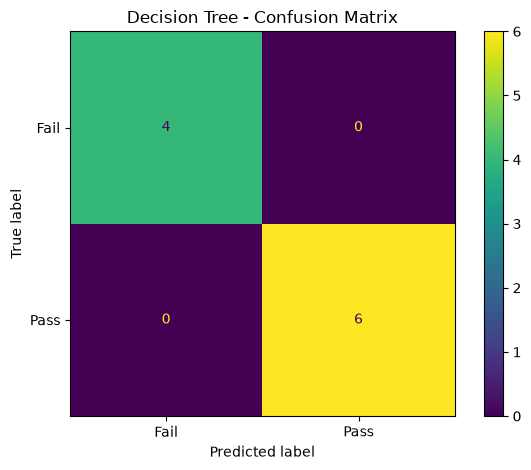


Random Forest
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         4
        Pass       1.00      1.00      1.00         6

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



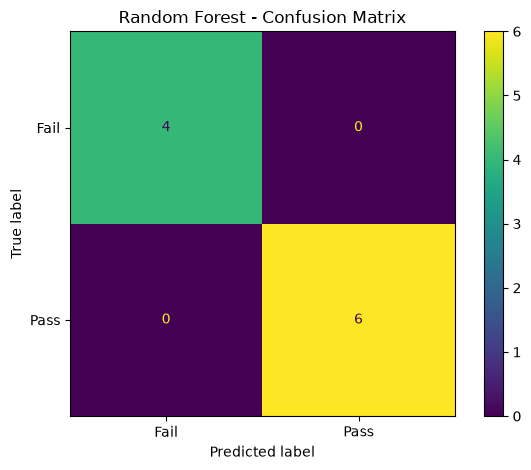


MODEL COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Decision Tree,100.0,100.0,100.0,100.0
1,Random Forest,100.0,100.0,100.0,100.0


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Compare the trained models
models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test, y_pred, pos_label="Pass",
                            zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, y_pred, pos_label="Pass",
                         zero_division=0) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, y_pred, pos_label="Pass",
                     zero_division=0) * 100, 2
        )
    })

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)
    print(classification_report(y_test, y_pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Fail", "Pass"],
        display_labels=["Fail", "Pass"],
        values_format="d"
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

# Display model comparison
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df)

In [45]:
import pandas as pd

new_student = pd.DataFrame([{
    "Age": 18,
    "Study_Hours_Per_Week": 7,
    "Attendance_Percent": 90,
    "Previous_Failures": 0,
    "Absences": 2,
    "Previous_Test_Score": 80
}])

prediction = rf_model.predict(new_student)[0]

print("STUDENT PERFORMANCE PREDICTION")
print("--------------------------------")
print("Age: 18")
print("Study Hours Per Week: 7")
print("Attendance: 90%")
print("Previous Failures: 0")
print("Absences: 2")
print("Previous Test Score: 80")

print("\nPredicted Final Result:", prediction)

probabilities = rf_model.predict_proba(new_student)[0]

print("\nEstimated Probabilities:")
for result, probability in zip(rf_model.classes_, probabilities):
    print(f"{result}: {probability * 100:.2f}%")

STUDENT PERFORMANCE PREDICTION
--------------------------------
Age: 18
Study Hours Per Week: 7
Attendance: 90%
Previous Failures: 0
Absences: 2
Previous Test Score: 80

Predicted Final Result: Pass

Estimated Probabilities:
Fail: 9.00%
Pass: 91.00%


In [46]:
from IPython.display import display, Markdown

display(Markdown("""
# Student Performance Prediction – Result Analysis

## Input Details

| Parameter | Value |
|---|---:|
| Age | 18 |
| Study Hours Per Week | 7 |
| Attendance | 90% |
| Previous Failures | 0 |
| Absences | 2 |
| Previous Test Score | 80 |

## Prediction Output

- **Predicted Result:** Pass
- **Estimated Pass Score:** 91%
- **Estimated Fail Score:** 9%

## Interpretation

The trained Random Forest classifier predicts that the sample
student will pass based on the supplied input features.

The model assigns a 91% score to Pass and a 9% score to Fail.
These values are model probability estimates, not validated
real-world probabilities.

Since the model was trained using only 50 synthetic student
records, this prediction is intended for educational demonstration.
It should not be used to make actual academic decisions.
"""))


# Student Performance Prediction – Result Analysis

## Input Details

| Parameter | Value |
|---|---:|
| Age | 18 |
| Study Hours Per Week | 7 |
| Attendance | 90% |
| Previous Failures | 0 |
| Absences | 2 |
| Previous Test Score | 80 |

## Prediction Output

- **Predicted Result:** Pass
- **Estimated Pass Score:** 91%
- **Estimated Fail Score:** 9%

## Interpretation

The trained Random Forest classifier predicts that the sample
student will pass based on the supplied input features.

The model assigns a 91% score to Pass and a 9% score to Fail.
These values are model probability estimates, not validated
real-world probabilities.

Since the model was trained using only 50 synthetic student
records, this prediction is intended for educational demonstration.
It should not be used to make actual academic decisions.


In [47]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}

comparison = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    comparison.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(
            precision_score(y_test, y_pred, pos_label="Pass", zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, y_pred, pos_label="Pass", zero_division=0) * 100, 2
        ),
        "F1 Score (%)": round(
            f1_score(y_test, y_pred, pos_label="Pass", zero_division=0) * 100, 2
        )
    })

comparison_df = pd.DataFrame(comparison)

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Decision Tree,100.0,100.0,100.0,100.0
1,Random Forest,100.0,100.0,100.0,100.0


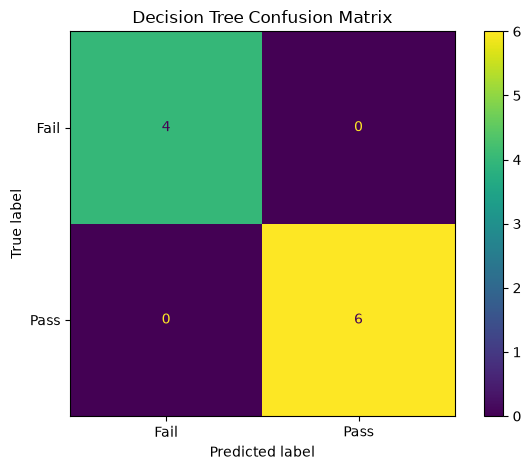

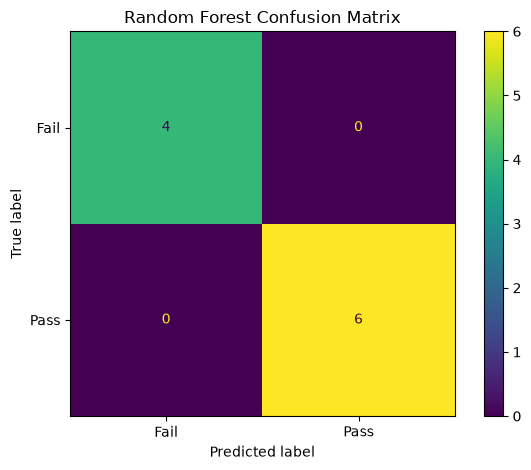

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in {
    "Decision Tree": dt_model,
    "Random Forest": rf_model
}.items():

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        labels=["Fail", "Pass"],
        display_labels=["Fail", "Pass"],
        values_format="d"
    )

    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()